<a href="https://colab.research.google.com/github/Manish-kumar19/manishkumar19.github.io/blob/main/Logistic_regression(classification).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A. Introduction of logistic Regression in ML.
### 1. What is Logistic regression ?
#### Logistic Regression is a supervised machine learning algorithm used mainly for classification problems.It predicts the probability that a given input belongs to a particular class.
#### For example: 1. Whether an email is Spam or Not Spam.
#### 2. Whether a customer will leave a company or stay.
#### 3. Whether a patient has a disease or does not have a disease.
#### 4. Whether a bank loan should be approved or rejected.



### 2. Why is it called Logistic Regression?
It is called Logistic Regression because it uses the logistic (sigmoid) function to convert a linear combination of input features into a probability between 0 and 1.

The general formula is:

###       P(y=1)=1/1+e^-2

### 3. Why do we use Logistic Regression?
We use Logistic Regression because many real-world problems require predicting categories rather than continuous numerical values.

For example:

Problem                   -               Prediction

Email classification         -            Spam / Not Spam

Disease prediction-Positive / Negative

Customer churn-Leave / Stay

Loan prediction-Approved / Rejected

Fraud detection-Fraud / Genuine

Its major benefit is that it provides probabilities, making predictions easier to interpret.



### 4. Types of Logistic Regression
There are three major types:

1. Binary Logistic Regression

Used when there are only two possible classes.

Examples:

i. Yes / No.

ii. 0 / 1.

iii. Spam / Not Spam.

2. Multinomial Logistic Regression

Used when there are three or more unordered classes.

Examples:

i. Cat / Dog / Horse.

ii. Red / Green / Blue.

3. Ordinal Logistic Regression

Used when the target classes have a meaningful order.

Examples:

i. Poor / Average / Good / Excellent.

ii. Low / Medium / High.



# B. Import Labraries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [48]:
from sklearn. model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate, cross_val_score
from sklearn. metrics import classification_report, accuracy_score, confusion_matrix
from sklearn. linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# C. Load dataset.


In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/Manish-kumar19/manishkumar19.github.io/main/diabetes_dataset.csv")

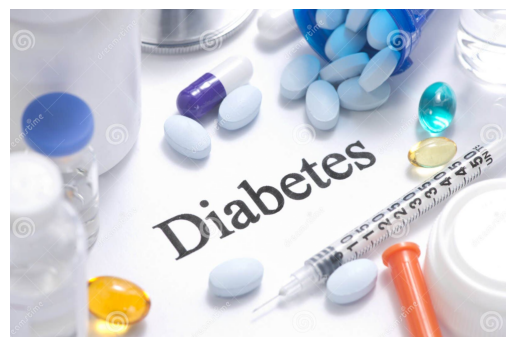

In [60]:
import matplotlib.image as mpimg

img = mpimg.imread('/content/Screenshot 2026-10-31 230243.png')

plt.imshow(img)
plt.axis('off')
plt.show()


# D. Data preprocessing in Logisitc regression.
## 1. Exploratory data Analysis (EDA) and clean the data.

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [10]:
df.nunique()

,0
Pregnancies,17
Glucose,136
BloodPressure,47
SkinThickness,51
Insulin,186
BMI,248
DiabetesPedigreeFunction,517
Age,52
Outcome,2


In [11]:
df.value_counts()

Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI   DiabetesPedigreeFunction  Age  Outcome
12           140      82             43             325      39.2  0.528                     58   1          1
             121      78             17             0        26.5  0.259                     62   0          1
             106      80             0              0        23.6  0.137                     44   0          1
             100      84             33             105      30.0  0.488                     46   0          1
             92       62             7              258      27.6  0.926                     44   1          1
                                                                                                            ..
0            78       88             29             40       36.9  0.434                     21   0          1
             74       52             10             36       27.8  0.269                     22   0          1
             73       0              0              0        21.1  0.342                     25   0          1
             67       76             0              0        45.3  0.194                     46   0          1
             57       60             0              0        21.7  0.735                     67   0          1
Name: count, Length: 768, dtype: int64

# Detect the outliers.

<Axes: >

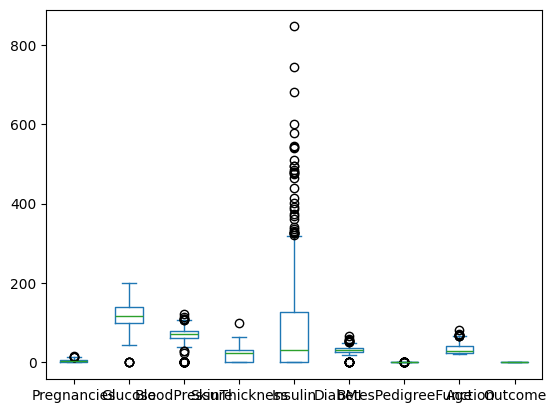

In [12]:
df[["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]].plot(kind="box")

In [13]:
def remove_outlier(df_input):
    Q1 = df_input.quantile(0.25)
    Q3 = df_input.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return lower, upper

## Remove the outliers one-by-one.

<Axes: >

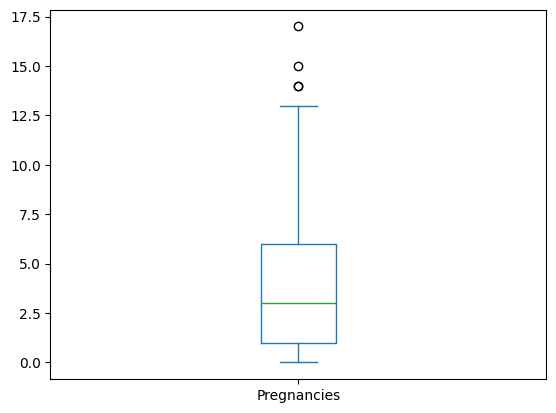

In [14]:
df["Pregnancies"].plot(kind="box")

<Axes: >

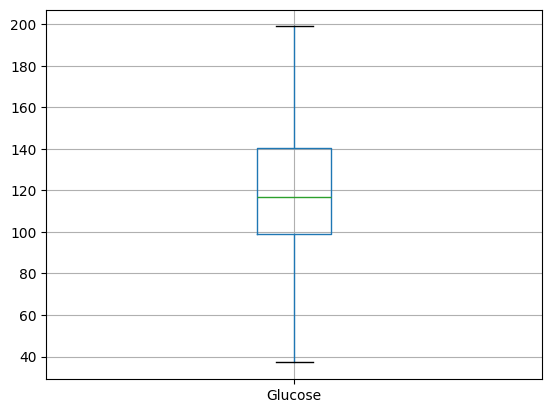

In [15]:
low, high = remove_outlier(df["Glucose"])
df["Glucose"] = np.where(df["Glucose"] <= low, low, df["Glucose"])
df["Glucose"] = np.where(df["Glucose"] >= high, high, df["Glucose"])
df.boxplot(column="Glucose")

<Axes: >

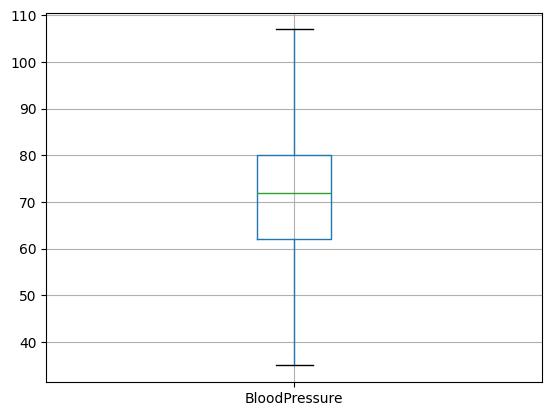

In [16]:
low, high = remove_outlier(df["BloodPressure"])
df["BloodPressure"] = np.where(df["BloodPressure"] <= low, low, df["BloodPressure"])
df["BloodPressure"] = np.where(df["BloodPressure"] >= high, high, df["BloodPressure"])
df.boxplot(column="BloodPressure")

<Axes: >

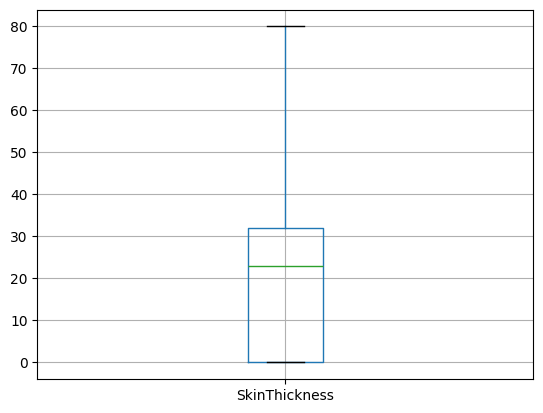

In [17]:
low, high = remove_outlier(df["SkinThickness"])
df["SkinThickness"] = np.where(df["SkinThickness"] <= low, low, df["SkinThickness"])
df["SkinThickness"] = np.where(df["SkinThickness"] >= high, high, df["SkinThickness"])
df.boxplot(column="SkinThickness")

<Axes: >

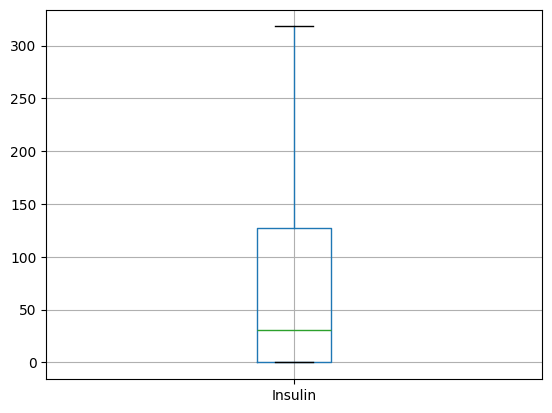

In [18]:
low, high = remove_outlier(df["Insulin"])
df["Insulin"] = np.where(df["Insulin"] <=low, low, df["Insulin"])
df["Insulin"] = np.where(df["Insulin"] >= high, high, df["Insulin"])
df.boxplot(column="Insulin")

<Axes: >

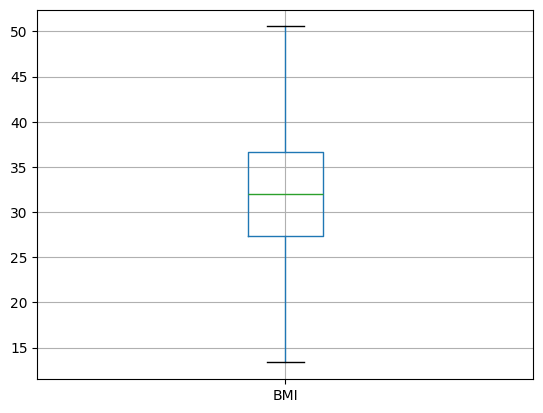

In [19]:
low,high= remove_outlier(df["BMI"])
df["BMI"] = np.where(df["BMI"] <=low, low, df["BMI"])
df["BMI"] = np.where(df["BMI"] >= high, high, df["BMI"])
df.boxplot(column="BMI")

<Axes: >

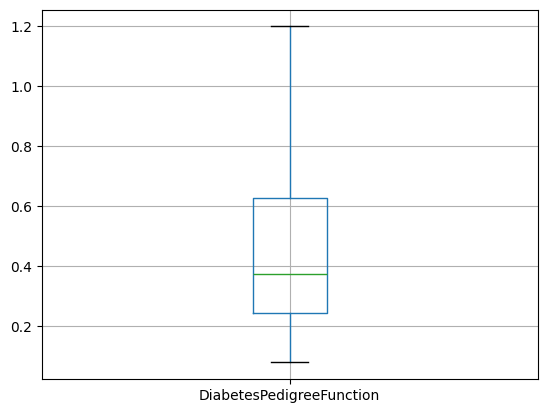

In [20]:
low,high= remove_outlier(df["DiabetesPedigreeFunction"])
df["DiabetesPedigreeFunction"] = np.where(df["DiabetesPedigreeFunction"] <=low, low, df["DiabetesPedigreeFunction"])
df["DiabetesPedigreeFunction"] = np.where(df["DiabetesPedigreeFunction"] >= high, high, df["DiabetesPedigreeFunction"])
df.boxplot(column="DiabetesPedigreeFunction")

<Axes: >

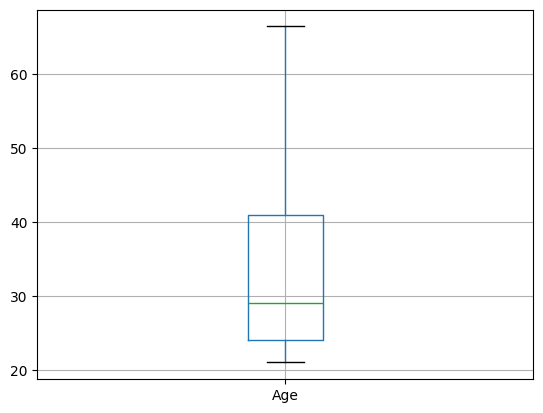

In [21]:
low,high= remove_outlier(df["Age"])
df["Age"] = np.where(df["Age"] <=low, low, df["Age"])
df["Age"] = np.where(df["Age"] >= high, high, df["Age"])
df.boxplot(column="Age")

<Axes: >

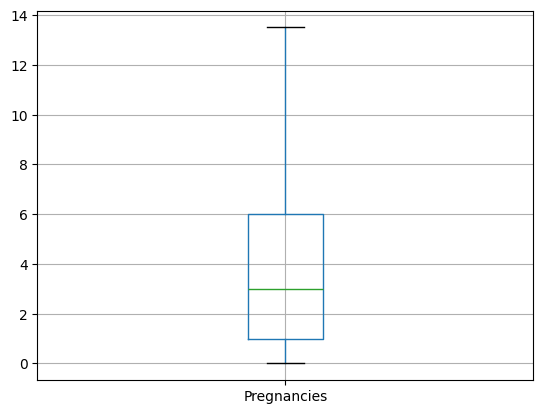

In [22]:
low,high= remove_outlier(df["Pregnancies"])
df["Pregnancies"] = np.where(df["Pregnancies"] <=low, low, df["Pregnancies"])
df["Pregnancies"] = np.where(df["Pregnancies"] >= high, high, df["Pregnancies"])
df.boxplot(column="Pregnancies")

### Plot boxplot again to see outliers.

<Axes: >

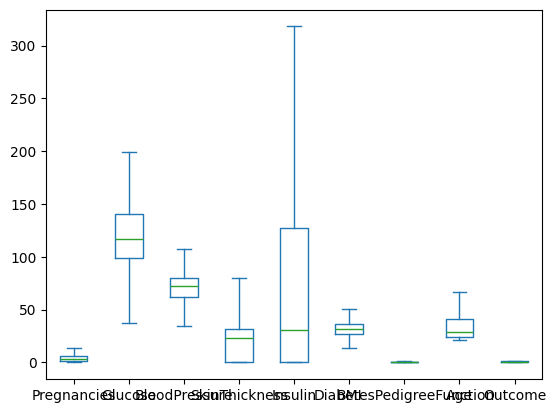

In [23]:
df[["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]].plot(kind="box")

# Bivariate/Multivariate Analysis (Analyzing Relationship).

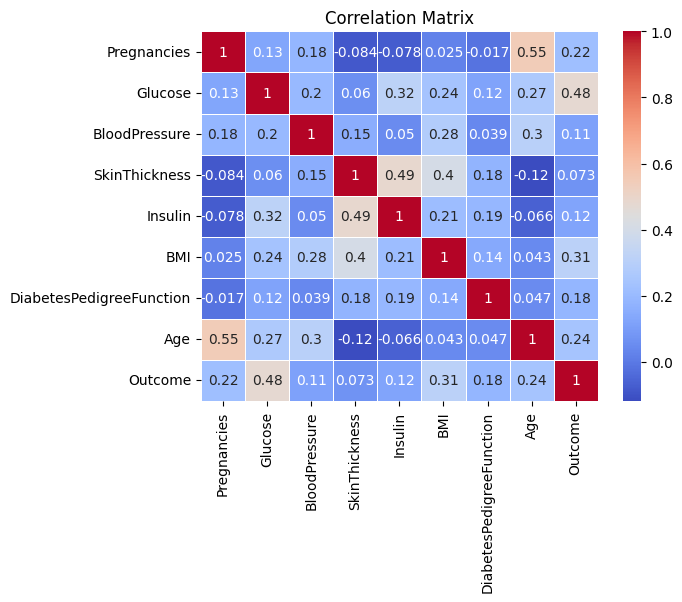

In [24]:
sns.heatmap(df.corr(), annot=True, linewidths=0.5, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

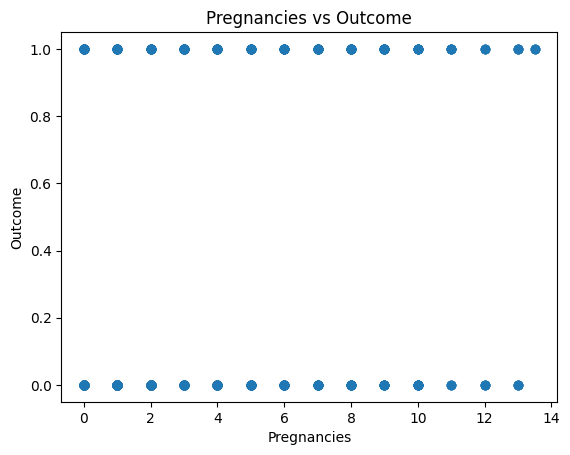

In [25]:
plt.scatter(x="Pregnancies", y="Outcome", data=df)
plt.xlabel("Pregnancies")
plt.ylabel("Outcome")
plt.title("Pregnancies vs Outcome")
plt.show()

# E. Evaluation.
## Separate the data into x and y.

In [26]:
x = df.drop("Outcome", axis=1)
y = df["Outcome"]

## Apply Train test split method.

In [27]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3, random_state=42)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(537, 8) (231, 8) (537,) (231,)


In [28]:
logmodel = LogisticRegression()
logmodel.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

## Leakage-save pipelines.

In [29]:
model = {"LogisitcRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=42))}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(model)

{'LogisitcRegression': Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=3000, random_state=42))])}


## Stratified k fold.

In [30]:
stkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
score = cross_val_score(model["LogisitcRegression"], x, y, cv=stkf, scoring="accuracy")
print(score)
print("Mean accuracy:", score.mean())

[0.76623377 0.79220779 0.78571429 0.77777778 0.76470588]
Mean accuracy: 0.7773279008573126


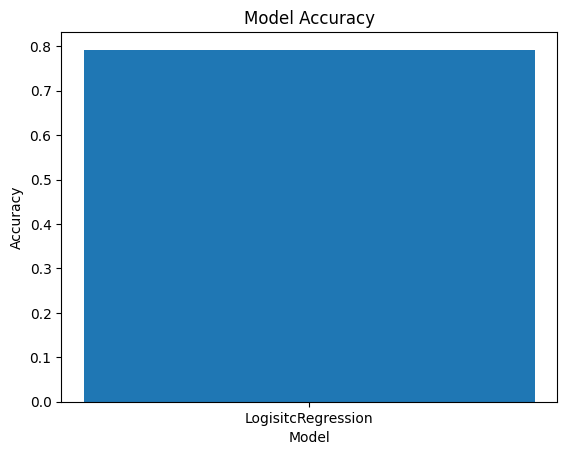

In [31]:
plt.bar(model.keys(), score)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.show()

## Classification report.



In [53]:
log_train_pred = logmodel.predict(x_train)
log_test_pred = logmodel.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, log_train_pred)
test_accuracy = accuracy_score(y_test, log_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

# Check overfitting
if train_accuracy - test_accuracy > 0.10:
    print("Model is Overfitting")

elif train_accuracy - test_accuracy > 0.05:
    print("Model has Some Overfitting")

else:
    print("Model is Not Showing Strong Signs of Overfitting")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, log_test_pred))


Training Accuracy: 0.7858472998137802
Testing Accuracy: 0.7445887445887446
Model is Not Showing Strong Signs of Overfitting

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       151
           1       0.64      0.61      0.62        80

    accuracy                           0.74       231
   macro avg       0.72      0.71      0.72       231
weighted avg       0.74      0.74      0.74       231



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

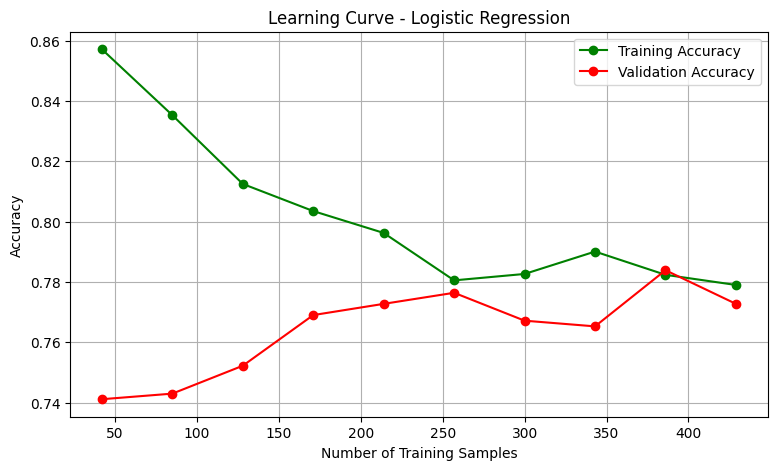

In [55]:
from sklearn.model_selection import learning_curve

# Learning curve
train_sizes, train_scores, test_scores = learning_curve(
    logmodel,
    x_train,
    y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

# Calculate mean accuracy
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(train_sizes, train_mean,
         marker='o', color='green',
         label='Training Accuracy')

plt.plot(train_sizes, test_mean,
         marker='o', color='red',
         label='Validation Accuracy')

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()


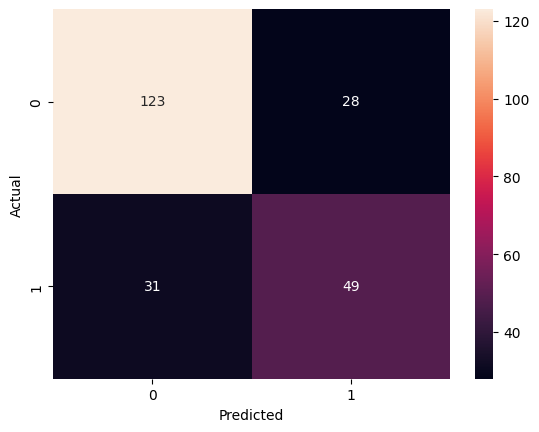

In [44]:
cm = pd.crosstab(y_test, y_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

# F. Compare with 2 another algo.


In [43]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

### i. KNeighborsClassifier.

In [52]:
knnmodel = KNeighborsClassifier(n_neighbors=5)

# Train model
knnmodel.fit(x_train, y_train)

# Predictions
knn_train_pred = knnmodel.predict(x_train)
knn_test_pred = knnmodel.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, knn_train_pred)
test_accuracy = accuracy_score(y_test, knn_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

# Check overfitting
if train_accuracy - test_accuracy > 0.10:
    print("Model is Overfitting")

elif train_accuracy - test_accuracy > 0.05:
    print("Model has Some Overfitting")

else:
    print("Model is Not Showing Strong Signs of Overfitting")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, knn_test_pred))


Training Accuracy: 0.8044692737430168
Testing Accuracy: 0.6883116883116883
Model is Overfitting

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.75      0.76       151
           1       0.55      0.56      0.56        80

    accuracy                           0.69       231
   macro avg       0.66      0.66      0.66       231
weighted avg       0.69      0.69      0.69       231



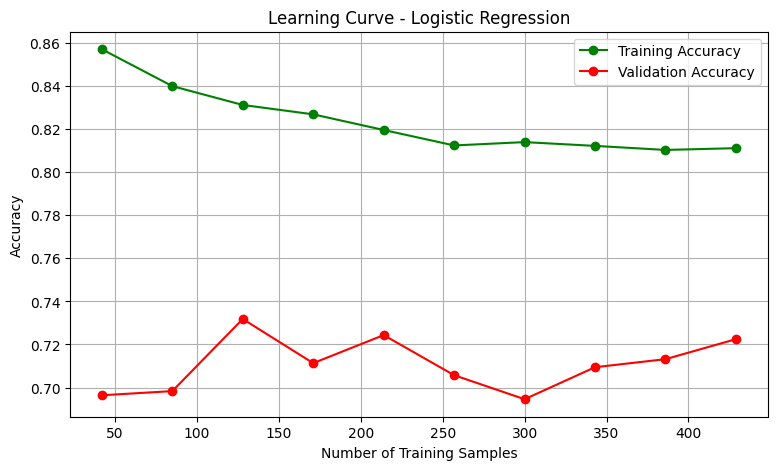

In [56]:
# Learning curve
train_sizes, train_scores, test_scores = learning_curve(
    knnmodel,
    x_train,
    y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

# Calculate mean accuracy
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(train_sizes, train_mean,
         marker='o', color='green',
         label='Training Accuracy')

plt.plot(train_sizes, test_mean,
         marker='o', color='red',
         label='Validation Accuracy')

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()


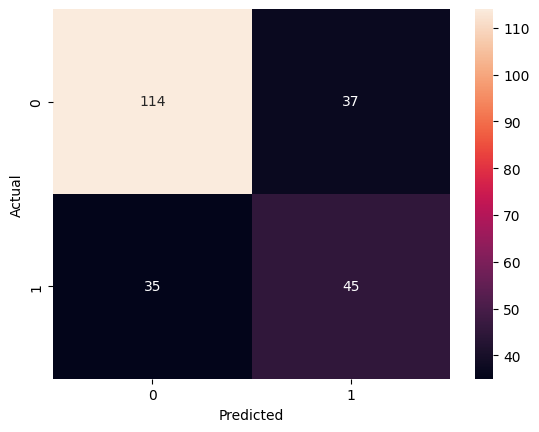

In [45]:
cm = pd.crosstab(y_test, knn_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

### ii. Naive bayes.

In [41]:
nbmodel = GaussianNB()
nbmodel.fit(x_train, y_train)

nb_pred = nbmodel.predict(x_test)
print(classification_report(y_test, nb_pred))

              precision    recall  f1-score   support

           0       0.81      0.74      0.77       151
           1       0.58      0.66      0.62        80

    accuracy                           0.71       231
   macro avg       0.69      0.70      0.69       231
weighted avg       0.73      0.71      0.72       231



In [57]:
# Predictions
nb_train_pred = nbmodel.predict(x_train)
nb_test_pred = nbmodel.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, nb_train_pred)
test_accuracy = accuracy_score(y_test, nb_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

# Check overfitting
if train_accuracy - test_accuracy > 0.10:
    print("Model is Overfitting")

elif train_accuracy - test_accuracy > 0.05:
    print("Model has Some Overfitting")

else:
    print("Model is Not Showing Strong Signs of Overfitting")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, nb_test_pred))


Training Accuracy: 0.7579143389199255
Testing Accuracy: 0.7142857142857143
Model is Not Showing Strong Signs of Overfitting

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.74      0.77       151
           1       0.58      0.66      0.62        80

    accuracy                           0.71       231
   macro avg       0.69      0.70      0.69       231
weighted avg       0.73      0.71      0.72       231



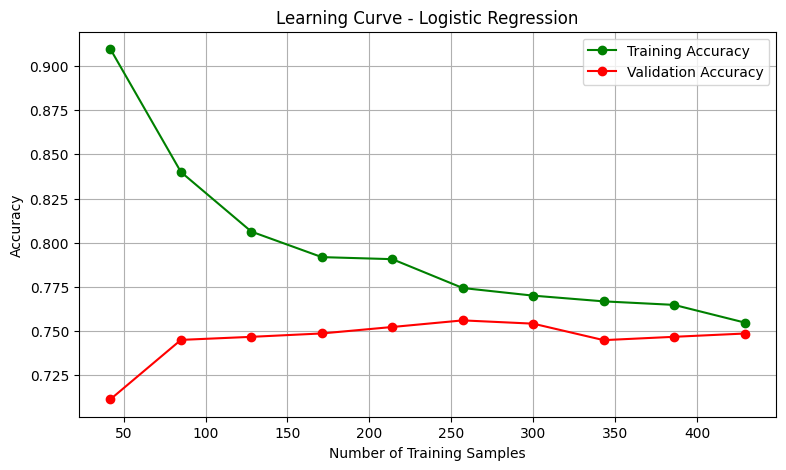

In [58]:
# Learning curve
train_sizes, train_scores, test_scores = learning_curve(
    nbmodel,
    x_train,
    y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

# Calculate mean accuracy
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(train_sizes, train_mean,
         marker='o', color='green',
         label='Training Accuracy')

plt.plot(train_sizes, test_mean,
         marker='o', color='red',
         label='Validation Accuracy')

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()


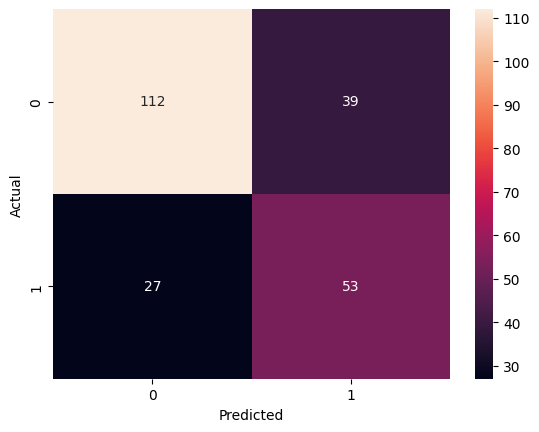

In [46]:
cm = pd.crosstab(y_test, nb_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(cm, annot=True, fmt="d")
plt.show()

## Why logistic regression is better than others.

i. Higher accuracy:Logistic regression Algorithm  achieves 74% accuracy, meaning it correctly classifies approximately 74% of the test samples.

ii. Higher F1-score: Its macro F1-score of 0.72 is higher than KNeighbors Algorithm (0.66) and naive bayes Algorithm (0.69).

iii. Better precision: It achieves 0.72 macro precision, indicating better overall prediction reliability.

iv. Better balance: It performs consistently better across most evaluation metrics.

v. Better class 1 F1-score: It achieves 0.62, matching Algorithm  naive bayes and outperforming Algorithm KNeighbors.



# G. Advantages and Disadvantages of Logistic regression.
##A. Advantages of Logistic Regression:

i. Easy to understand: Simple to learn and implement.

ii. Fast training: Requires less training time.

iii. Easy interpretation: Coefficients help understand the relationship between features and the target.

iv. Probability prediction: Predicts the probability of an outcome.

v. Less computational cost: Requires fewer resources.

vi. Good for classification: Works well for binary classification problems.

vii. Less prone to overfitting: Regularization (L1 and L2) helps prevent overfitting.

##B. Disadvantages of Logistic Regression:

i. Linear relationship: Assumes a linear relationship between input features and log-odds.

ii. Not suitable for complex data: May perform poorly on highly complex, nonlinear patterns.

iii. Sensitive to outliers: Outliers can affect model performance.

iv. Feature engineering: May require feature selection and transformation.

v. Multicollinearity: Highly correlated features can affect coefficient interpretation.

vi. Class imbalance: May perform poorly when one class has significantly more samples than another.

vii. Limited flexibility: Cannot naturally capture complex relationships without additional feature engineering.

